# First analysis to load AV_Dome data from RDSS and get Learning curves 

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
# import seaborn as sns
import os
from pathlib import Path
import xarray as xr
from modules.loading_functions import load_sessions



In [ ]:
if 1:
    # This assumes that you mounted the AV_Dome prject folder as a mapped network drive "Z:". If you mounted it to a different location, please change the path below.
    root_folder = Path(r"Z:\AV_Dome")

    # list all available subjects:
    dirs = [p for p in root_folder.iterdir() if p.is_dir()]

    all_subjects = []
    for i in dirs:
        subject = i.name.split("sub-")[-1]
        all_subjects.append(subject)
    #

    # ## OVERWRITE FOR NOW!!!
    all_subjects = ["GN011", "GN012", "GN013", "GN014", "GN015"]
    # all_subjects = ["Gary"]

    df = load_sessions(root_folder, all_subjects)
else:
    # This assumes that you mounted the AV_Dome prject folder as a mapped network drive "Z:". If you mounted it to a different location, please change the path below.
    root_folder = Path(r"Z:\AV_Dome_ClosedLoop")

    # list all available subjects:
    dirs = [p for p in root_folder.iterdir() if p.is_dir()]

    all_subjects = []
    for i in dirs:
        subject = i.name.split("sub-")[-1]
        all_subjects.append(subject)
    #

    # # ## OVERWRITE FOR NOW!!!
    # all_subjects = ["GN011", "GN012", "GN013", "GN014", "GN015"]

    df = load_sessions(root_folder, all_subjects)
#


In [ ]:
def compute_performance(dataFrame):
    # Not sure this is necesarry, but want to make sure I'm not manipulating the source!
    df = dataFrame.copy()
    
    # Current results output doesn't include both_spouts! Need to investigate and add this filter in the future, but for now, skip that mask.
    trialMask = ((df.correctResponse == "Correct") | (df.correctResponse == "Incorrect")) & \
                 (df.BothSpouts == "True") & \
                 (df.autoReward == "False") & \
                 (df.IsRepeat == "False") & \
                 ((df.RepeatCount).astype(int) == 0)  # Those two should be redundant but just in case
        
    trialCnt = np.sum(trialMask)
    df = df.loc[trialMask]

    rightResponses = (df.response == "Right").astype(np.float32)
    p_right = np.mean(rightResponses)
    correctResponses = (df.correctResponse == "Correct").astype(np.float32)
    performance = np.mean(correctResponses)
    return performance, trialCnt, p_right
#

In [ ]:
# df.
all_mice = np.sort(np.unique(df.subject))
all_mice = all_mice[all_mice != "Dummy"]

fig, ax = plt.subplots(2, np.max([2, len(all_mice)]), figsize=[14, 6])

# session_ids = list()
performance = list()
bias = list()
# trialCnt = list()
for subject_id, subject in enumerate(all_mice):
    session_ids = df[df.subject == subject].session_id.unique()
    performance.append(list())
    bias.append(list())
    # trialCnt.append(list())
    for session_id in np.sort(session_ids):
        try:
            session_df = df[(df.subject == subject) & (df.session_id == session_id)]
            
            if (subject == "GN012") & (session_id == 7):
                print("asd")
            
            perf, trialCnt, p_right = compute_performance(session_df)
            
            if trialCnt > 50:
                performance[subject_id].append(perf)
            #
        except Exception as e:
            pass
        #
    #
    
    c_ax = ax[0, subject_id]
    c_ax.plot([0, len(performance[subject_id])], [0.5, 0.5], "--r")
    c_ax.plot(performance[subject_id], "-o")
    c_ax.set_title(subject)
    c_ax.set_xlabel("# Sessions")
    c_ax.set_ylabel("Performance")
    c_ax.set_ylim([0.35, 1])
#

plt.tight_layout()
plt.show()


asd
<StringArray>
['GN013: 2026-08-25T13-30-32 - 0.9777778 - 45']
Length: 1, dtype: str
<StringArray>
['GN014: 2026-08-25T14-28-38 - 1.0 - 58']
Length: 1, dtype: str


: 

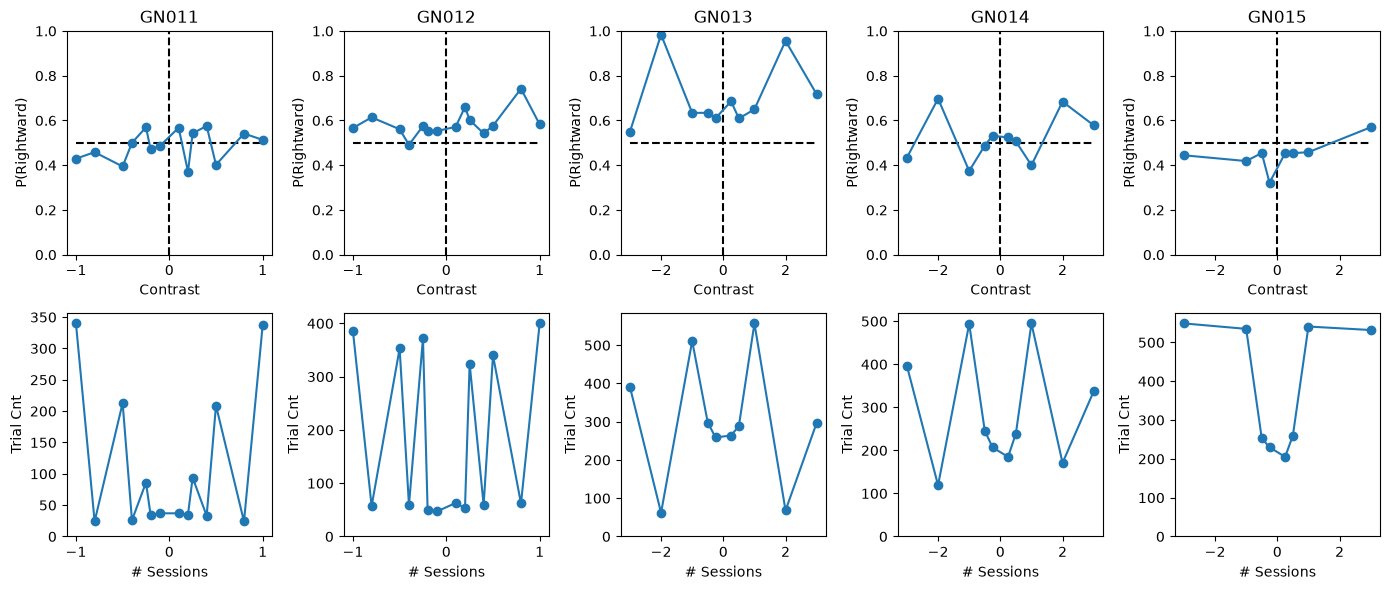

In [ ]:
# df.
all_mice = np.sort(np.unique(df.subject))
fig, ax = plt.subplots(2, np.max([2, len(all_mice)]), figsize=[14, 6])
for subject_id, subject in enumerate(all_mice):
    subject_df = df[df.subject == subject]
    
    # make left target negative
    visual_contrasts = np.sort(np.unique(subject_df.visualContrast.astype(float) * (1 - (2 * (subject_df.target_side == "Left").astype(float)))))
    # visual_contrasts = visual_contrasts[(visual_contrasts > -1) & (visual_contrasts < 1)]
    
    perf = np.empty([3, len(visual_contrasts)])
    perf[:] = np.nan
    for contrast_id, contrast in enumerate(visual_contrasts):
        perf[0, contrast_id] = contrast

        try:
            target_side = "Left" if contrast < 0 else "Right"
            contrast_df = subject_df[(subject_df.visualContrast.astype(float) == np.abs(contrast)) & (subject_df.target_side == target_side)]
            performance, trialCnt, p_right = compute_performance(contrast_df)
            perf[1, contrast_id] = p_right  # performance
            perf[2, contrast_id] = trialCnt
        except:
            perf[1, contrast_id] = np.nan
            perf[2, contrast_id] = 0
        #
    #

    c_ax = ax[0, subject_id]
    c_ax.plot([perf[0, :].min(), perf[0, :].max()], [0.5, 0.5], "--k")
    c_ax.plot([0, 0], [0, 1], "--k")
    c_ax.plot(perf[0, :], perf[1, :], "-o")
    c_ax.set_title(subject)
    c_ax.set_xlabel("Contrast")
    c_ax.set_ylabel("P(Rightward)")
    c_ax.set_ylim([0, 1])
    
    c_ax = ax[1, subject_id]
    c_ax.plot(perf[0, :], perf[2, :], "-o")
    # c_ax.plot(bias[subject_id], "-o")
    c_ax.set_xlabel("# Sessions")
    c_ax.set_ylabel("Trial Cnt")
    c_ax.set_ylim([0, perf[2, :].max() * 1.05])
# performance

plt.tight_layout()
plt.show()


In [ ]:
# # This is where loading is done and analysis can start...

# if "overall_df" not in locals():
#     overall_df = df.copy()
# else:
#     # For debugging and rerunnability
#     df = overall_df.copy()
# # 

# # Current results output doesn't include both_spouts! Need to investigate and add this filter in the future, but for now, skip that mask.
# trialMask = ((df.correctResponse == "Correct") | (df.correctResponse == "Incorrect")) & (df.BothSpouts == "True") & (df.autoReward == "False")
# df = df.loc[trialMask]

# correctResponses = (df.correctResponse == "Correct").astype(int)
# print(np.mean(correctResponses))  # Overall accuracy


In [ ]:
# visual_contrasts = np.unique(df.visualContrast).astype(float)  # loaded as str...
# visual_contrasts = np.concatenate((-visual_contrasts, visual_contrasts))  # represent left as negative contrasts
# visual_contrasts = np.sort(visual_contrasts)  # ascending order

# data = xr.Dataset()
# ds = xr.Dataset()
# for contrast in visual_contrasts:
#     side_str = "Left" if contrast < 0 else "Right"
#     df_contrast = df[(df.visualContrast.astype(float) == np.abs(contrast)) & (df.target_side == side_str)]
#     data[f"contrast_{contrast}"] = df_contrast
    
#     correctResponses = (df_contrast.response == "Correct").astype(int)
#     print(np.mean(correctResponses))  # accuracy
#     ds[f"contrast_{contrast}"] = 1 - np.mean(correctResponses) if contrast < 0 else np.mean(correctResponses)
# #

# # data
# # ds

# plt.plot(visual_contrasts, ds.to_array().values)
# plt.xlabel("Visual Contrast")
# plt.ylabel("Accuracy")
# plt.title("Performance across Visual Contrasts")
# plt.show()
